# Supermarket sales: first look

A first look at 1,000 sales from three branches, covering January to March 2019: quantity sold by city, then product line, gender and payment method in each city.

**This is sample data.** It's a widely shared practice dataset, not records from a real shop, so the patterns here show how to analyse sales data and shouldn't be read as facts about real customers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "supermarket_sales.csv"

In [3]:
df = pd.read_csv(DATA_PATH)
df

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,1/29/2019,13:46,Ewallet,40.35,4.761905,2.0175,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,3/2/2019,17:16,Ewallet,973.80,4.761905,48.6900,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,2/9/2019,13:22,Cash,31.84,4.761905,1.5920,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,2/22/2019,15:33,Cash,65.82,4.761905,3.2910,4.1


In [4]:
df.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,0.000000,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905,49.650000,10.00000


In [5]:
Yangon = df.query("City == 'Yangon'")
Yangon_sum = Yangon['Quantity'].sum()

Naypyitaw = df.query("City == 'Naypyitaw'")
Naypyitaw_sum = Naypyitaw['Quantity'].sum()

Mandalay= df.query("City == 'Mandalay'")
Mandalay_sum = Mandalay['Quantity'].sum()

quantity_sum_all = [Yangon_sum, Naypyitaw_sum, Mandalay_sum ]

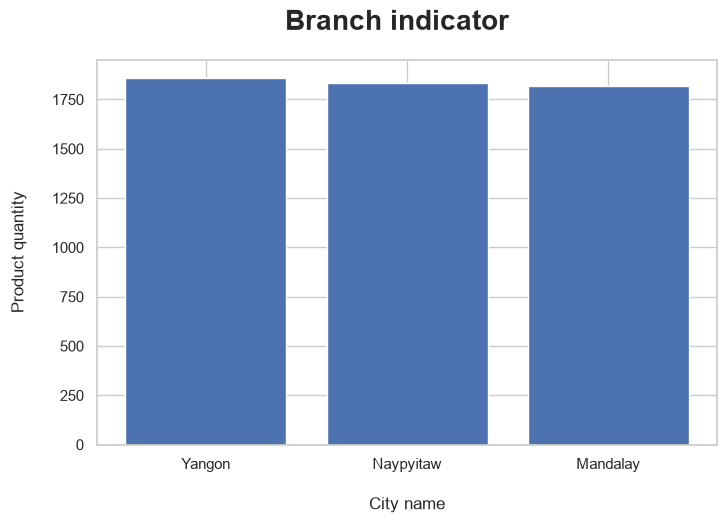

In [6]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(tuple(df['City'].unique()), quantity_sum_all)
ax.set( xlabel='\nCity name', ylabel='Product quantity\n')
plt.suptitle('Branch indicator',fontsize='20',fontweight='bold')
plt.show()

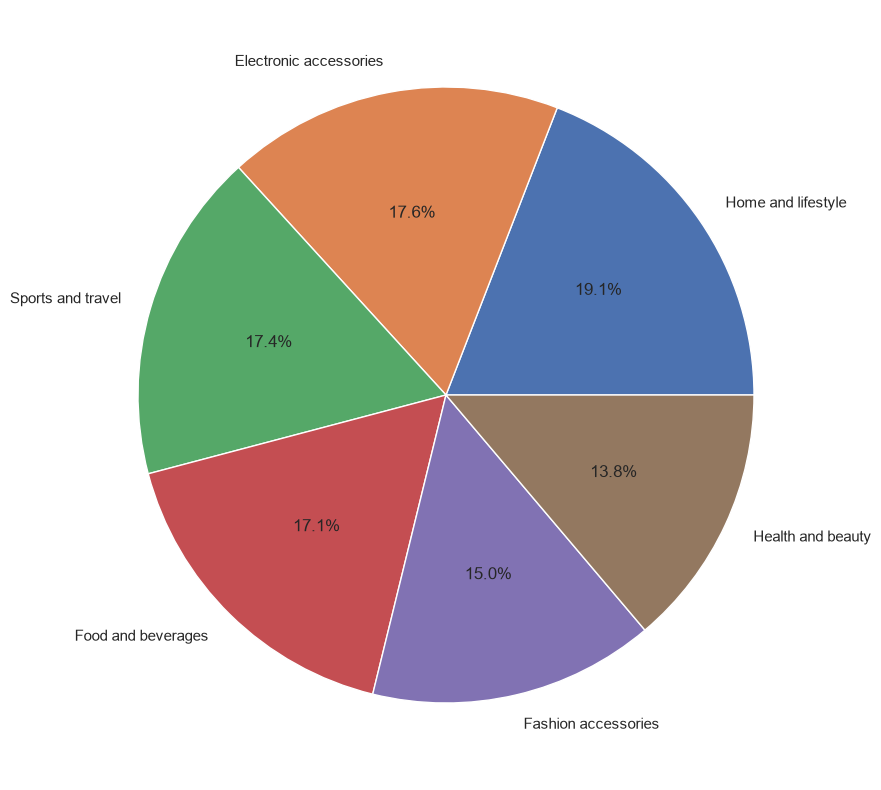

In [7]:
plt.figure(figsize=(20,10))
Yangon["Product line"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.show()

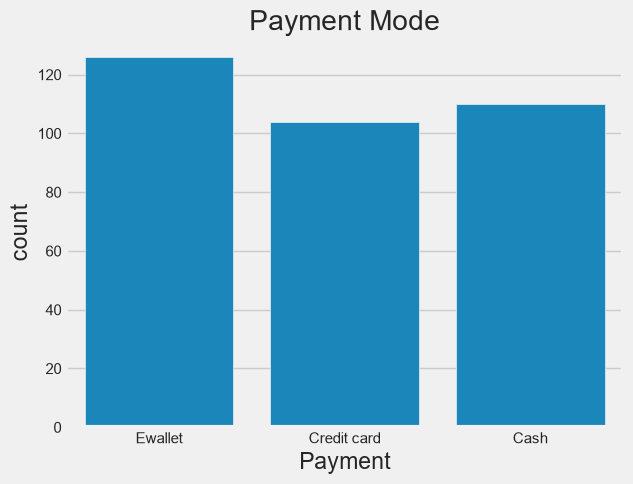

In [8]:
plt.style.use('fivethirtyeight')
sns.countplot(x="Payment", data =Yangon).set_title("Payment Mode")
plt.show()

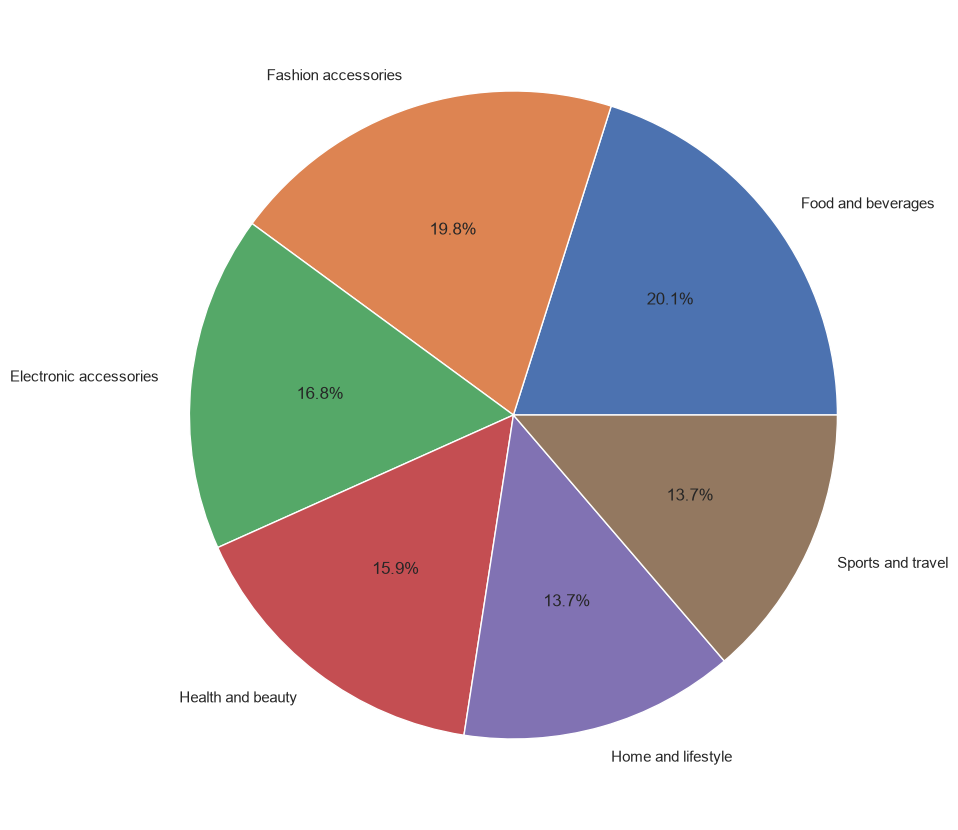

In [9]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(20,10))
Naypyitaw["Product line"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.show()

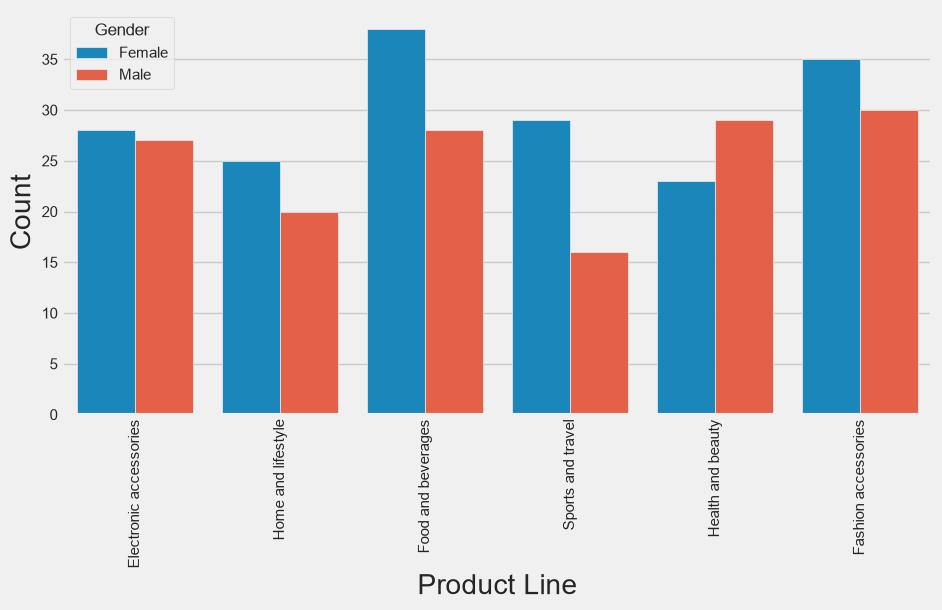

In [10]:
plt.style.use('fivethirtyeight')
plt.figure(figsize=(10, 5))
plt.xticks(rotation=90)
sns.countplot(x='Product line', data=Naypyitaw, hue='Gender')
plt.xlabel('Product Line', fontsize=20)
plt.ylabel('Count', fontsize=20);

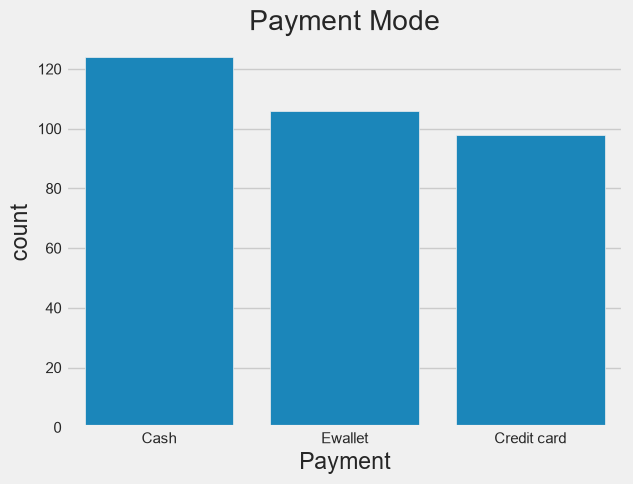

In [11]:
plt.style.use('fivethirtyeight')
sns.countplot(x="Payment", data=Naypyitaw).set_title("Payment Mode")
plt.show()

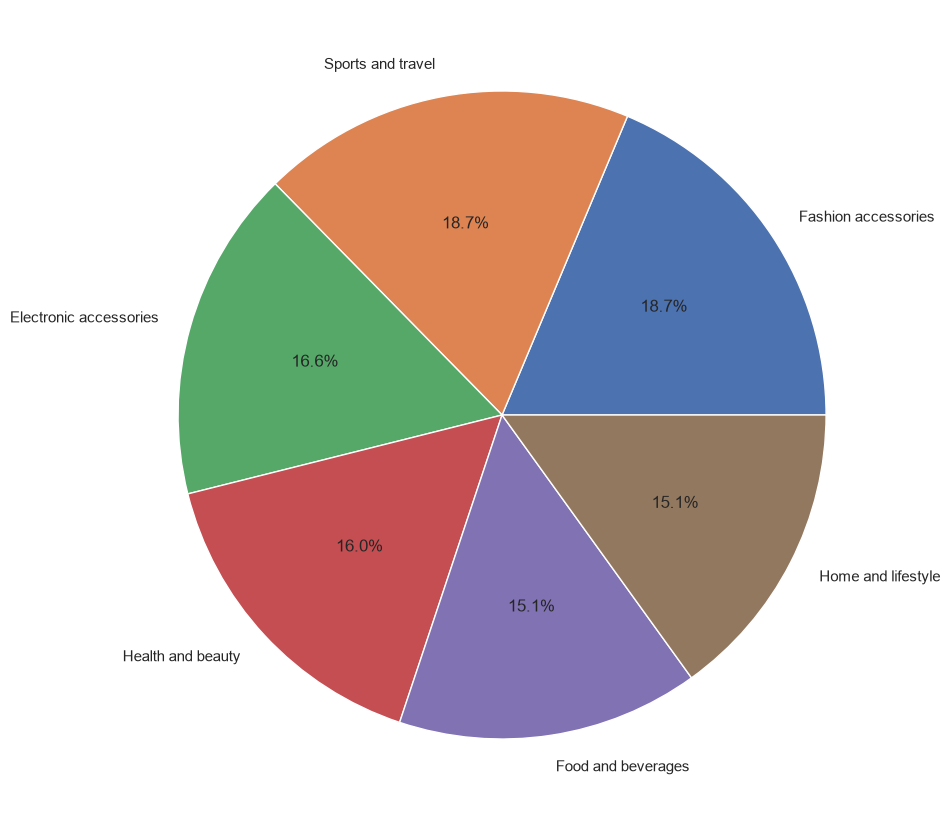

In [12]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(20,10))
Mandalay["Product line"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.show()

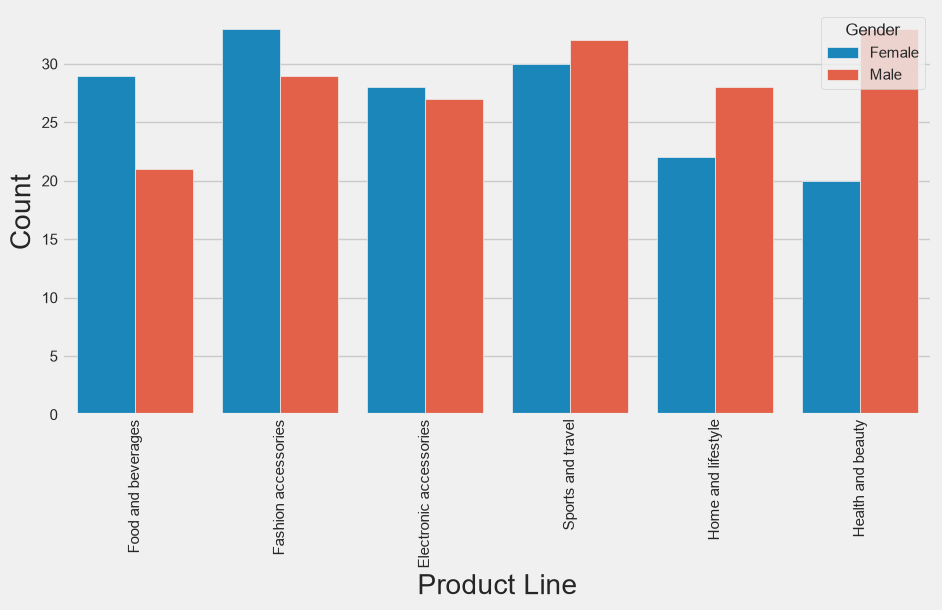

In [13]:
plt.style.use('fivethirtyeight')
plt.figure(figsize=(10, 5))
plt.xticks(rotation=90)
sns.countplot(x='Product line', data=Mandalay, hue='Gender')
plt.xlabel('Product Line', fontsize=20)
plt.ylabel('Count', fontsize=20);

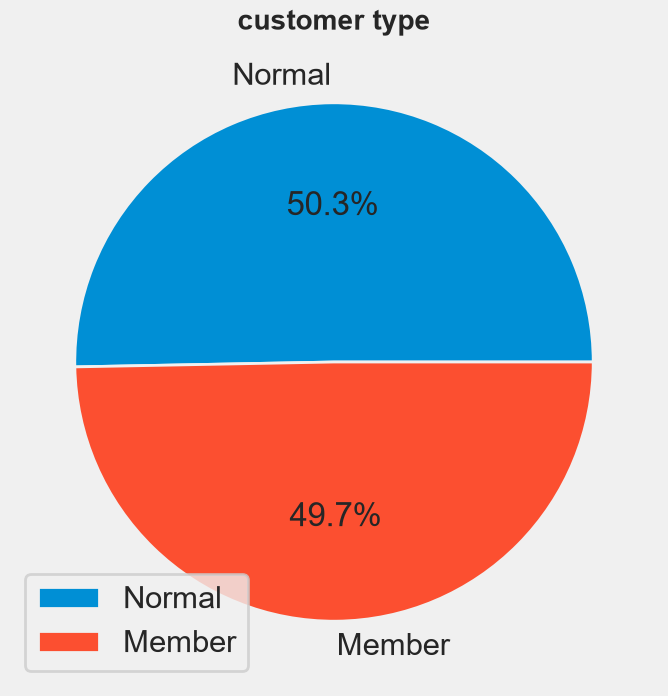

In [14]:
sns.set_context("poster")
plt.figure(figsize=(10,8))
Mandalay["Customer type"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.legend()
plt.title('customer type', fontsize=20,fontweight='bold')
plt.show()

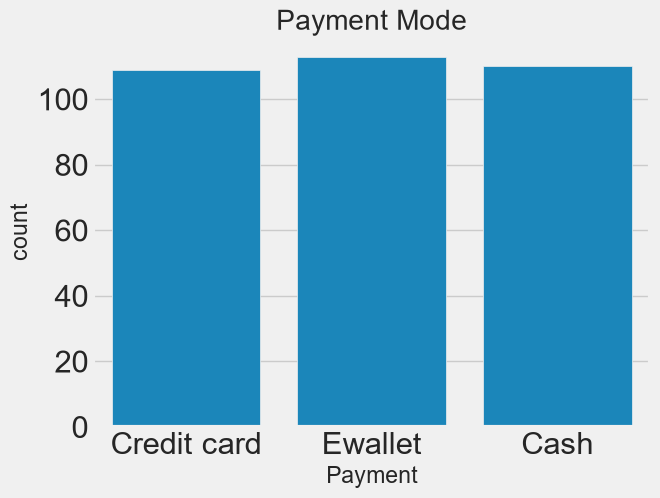

In [15]:
plt.style.use('fivethirtyeight')
sns.countplot(x="Payment", data =Mandalay).set_title("Payment Mode")
plt.show()